In [2]:
# load the dataset
import os
import sys
import pandas as pd
import json
load = True
if load:
    data_rand = pd.read_csv("edge_spen/r4_mean_50_rand.csv")
    

In [3]:
# Esplorare la struttura dei dati
print("Shape dei dati:")
print(f"rand: {data_rand.shape}")

print("\nColonne nei dati:")
print(data_rand.columns.tolist())
print("\nPrime righe (rand):")
print(data_rand.head())


Shape dei dati:
rand: (2100, 5)

Colonne nei dati:
['seed', 'n_special', 'beta', 'delta', 'r4_mean_50']

Prime righe (rand):
   seed  n_special  beta  delta  r4_mean_50
0     0          5   3.5    0.3   -2.316657
1     0          5   3.5    0.4   -4.163267
2     0          5   3.5    0.5   -2.563370
3     0          5   3.5    0.6   -2.974825
4     0          5   3.5    0.7   -2.591562


/tmp/ipykernel_26357/878463779.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5,


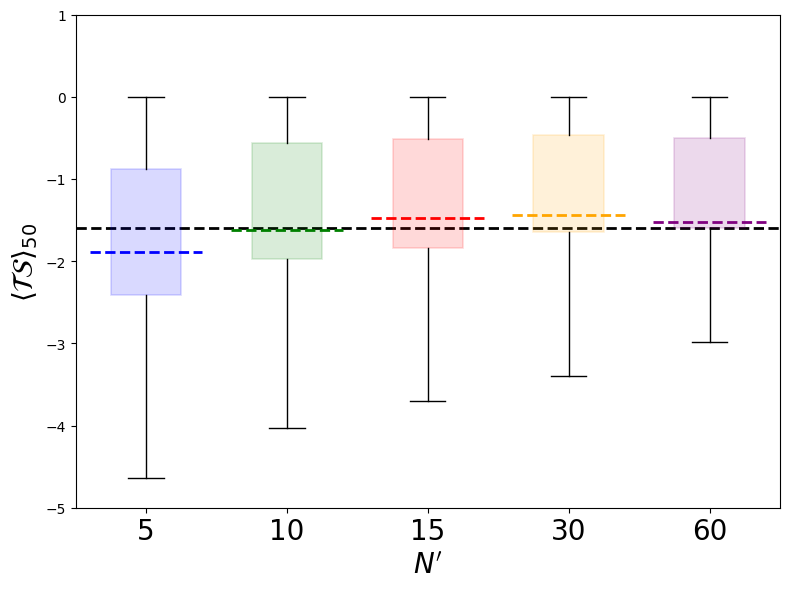

In [4]:
import matplotlib.pyplot as plt
import numpy as np

n_specials = sorted(data_rand['n_special'].unique())
colors = ['blue', 'green', 'red', 'orange', 'purple']

fig, ax = plt.subplots(figsize=(8, 6))

data_for_boxplot = []
labels = []

for n_s in n_specials:
    source_data = data_rand[data_rand['n_special'] == n_s]['r4_mean_50']
    if len(source_data) > 0:
        data_for_boxplot.append(source_data.values)
        labels.append(n_s)

positions = list(range(len(data_for_boxplot)))

# --- UPDATED: meanline abilitata, mediana nascosta ---
bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5,
                patch_artist=True, labels=labels, showfliers=False, zorder=2,
                showmeans=True, meanline=True, 
                medianprops={'linewidth': 0}) # Nasconde la mediana

# Styling dei box
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.15)
    patch.set_edgecolor(color)
    patch.set_linewidth(1.2)

# --- UPDATED: Styling e accorciamento delle linee della media ---
for mean, color in zip(bp['means'], colors):
    mean.set_color(color)
    mean.set_linewidth(2)
    
    # Rendi le linee della media più corte della larghezza del box (es. 75% della larghezza)
    x_data = mean.get_xdata() 
    center = np.mean(x_data)
    new_x_data = [center - (center - x_data[0]) * 1.6, center + (x_data[1] - center) * 1.6]
    mean.set_xdata(new_x_data)

# Lo scatter plot per i punti singoli è stato rimosso correttamente

# --- UPDATED: Linea della soglia più visibile e con un tratteggio diverso ('--') ---
ax.axhline(y=-1.6, color='black', linestyle='--', linewidth=2.0, zorder=1)

ax.set_ylim([-5, 1])
ax.set_xlabel(r'$N^{\prime}$', fontsize=20)
ax.set_ylabel(r'$\langle \mathcal{TS} \rangle_{50}$', fontsize=20)
ax.tick_params(axis='x', labelsize=20)

plt.tight_layout()
plt.show()

/tmp/ipykernel_23865/2901590071.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5,


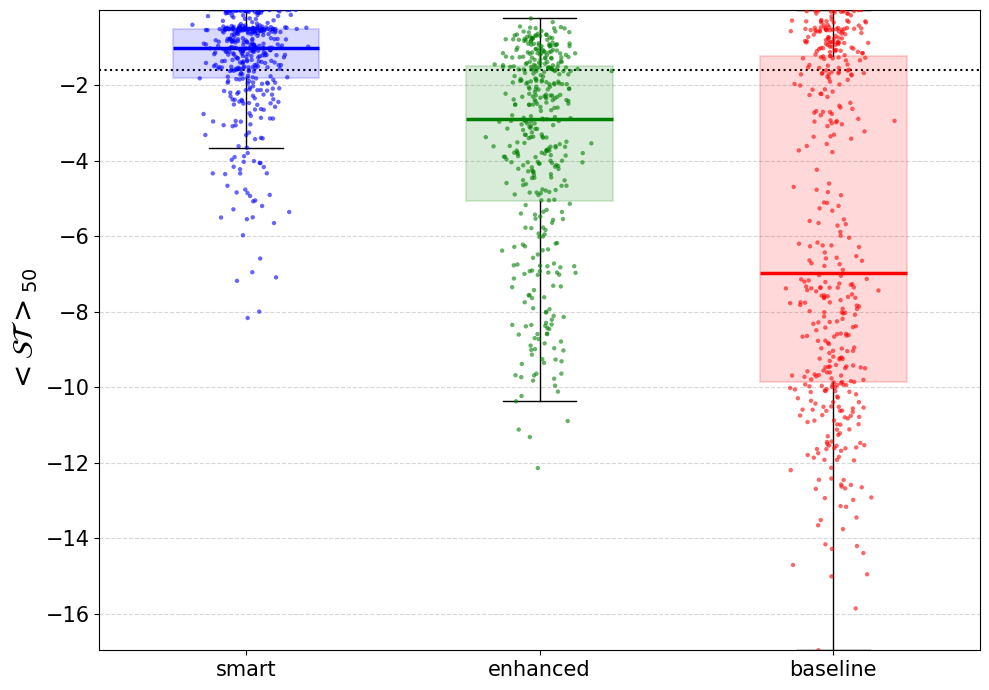

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Add a 'source' column to distinguish the datasets
data_rand['source'] = 'smart'
data_enh['source'] = 'enhanced'
data_base['source'] = 'baseline'

# Concatenate the data (this aggregates all beta and delta conditions automatically)
data_combined = pd.concat([data_rand, data_enh, data_base], ignore_index=True)

# Plot setup
fig, ax = plt.subplots(figsize=(10, 7))

sources_list = ['smart', 'enhanced', 'baseline']
colors = ['blue', 'green', 'red']
positions = range(len(sources_list))

# Prepare the aggregated data for each source
data_for_boxplot = []
for source in sources_list:
    source_data = data_combined[data_combined['source'] == source]['r4_mean_50'].values
    data_for_boxplot.append(source_data)

# Create the global boxplot (hiding default fliers to avoid duplicates)
bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, 
                patch_artist=True, labels=sources_list, showfliers=False, zorder=2)

# Style the boxes with high transparency
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.15)  # High transparency for the box fill
    patch.set_edgecolor(color)
    patch.set_linewidth(1.5)

# Style the median lines (full opacity for clear visibility)
for median, color in zip(bp['medians'], colors):
    median.set_color(color)
    median.set_linewidth(2.5)

# Overlay all individual data points across all configurations
for idx, source_data in enumerate(data_for_boxplot):
    # Add jitter to the X-axis to see the massive cloud of points clearly
    jitter = np.random.normal(0, 0.06, size=len(source_data))
    x_positions = np.full(len(source_data), positions[idx]) + jitter
    
    # Render points with strong opacity and smaller size since there are more data points now
    ax.scatter(x_positions, source_data, color=colors[idx], alpha=0.6, 
               edgecolors='none', s=10, zorder=3)

# Global plot formatting
ax.set_ylabel(r'$<\mathcal{ST}>_{50}$', fontsize=20)
# ax.set_title('Global Distribution by Scenario (Aggregated $\\beta$ and $\\delta$)', fontsize=14, fontweight='bold')
ax.set_ylim([data_combined['r4_mean_50'].min(), data_combined['r4_mean_50'].max()])
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=1)

# Add a horizontal dotted line at -1.6 in black
ax.axhline(y=-1.6, color='black', linestyle=':', linewidth=1.5, zorder=1)

# Clean up X-axis appearance
ax.tick_params(axis='x', labelsize=15, rotation=0)

# increase y thicks sizes
ax.tick_params(axis='y', labelsize=15)

plt.tight_layout()
plt.show()

# pop and pod

In [5]:
pop_pod_rand = pd.read_csv("edge_spen/pop_pod_last_rand.csv")
pop_pod_enh = pd.read_csv("pop_pod_last_enh.csv")
pop_pod_base = pd.read_csv("pop_pod_last_base.csv")

/tmp/ipykernel_23865/3416774543.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showfliers=False, zorder=2)
/tmp/ipykernel_23865/3416774543.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showfliers=False, zorder=2)
/tmp/ipykernel_23865/3416774543.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showflie

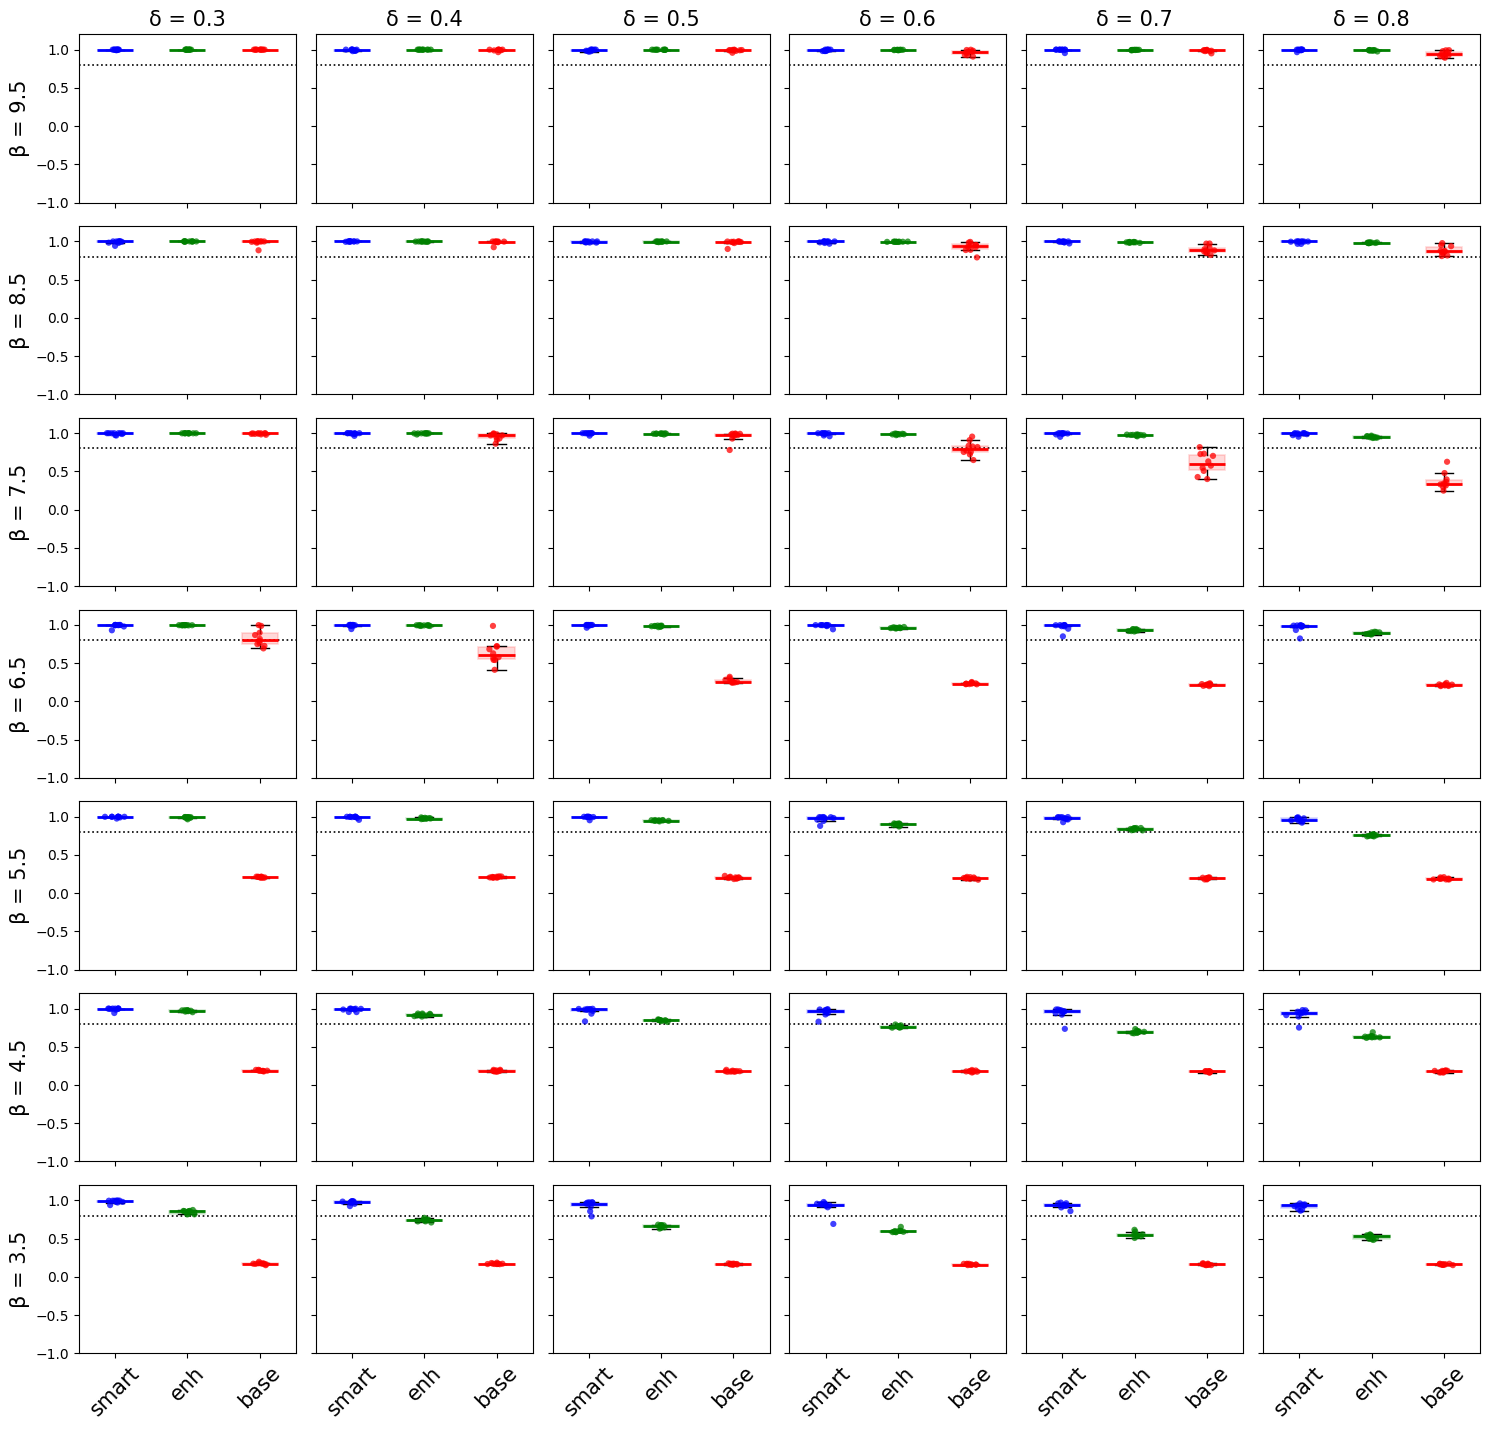

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# GRID: Boxplots of 'pod_last' for each (beta, delta) combination
pop_pod_rand['source'] = 'smart'
pop_pod_enh['source'] = 'enh'
pop_pod_base['source'] = 'base'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_enh, pop_pod_base], ignore_index=True)
betas = sorted(pop_pod_combined['beta'].unique(), reverse=True)
deltas = sorted(pop_pod_combined['delta'].unique())
fig, axes = plt.subplots(len(betas), len(deltas), figsize=(15, 15))
if len(betas) == 1:
    axes = axes.reshape(1, -1)
if len(deltas) == 1:
    axes = axes.reshape(-1, 1)
for i, beta in enumerate(betas):
    for j, delta in enumerate(deltas):
        ax = axes[i, j]
        mask = (pop_pod_combined['beta'] == beta) & (pop_pod_combined['delta'] == delta)
        subset = pop_pod_combined[mask]
        data_for_boxplot = []
        sources = []
        colors = ['blue', 'green', 'red']
        for source in ['smart', 'enh', 'base']:
            source_data = subset[subset['source'] == source]['pop_last']
            if len(source_data) > 0:
                data_for_boxplot.append(source_data.values)
                sources.append(source)
        if data_for_boxplot:
            positions = list(range(len(data_for_boxplot)))
            bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showfliers=False, zorder=2)
            for patch, color in zip(bp['boxes'], colors[:len(data_for_boxplot)]):
                patch.set_facecolor(color)
                patch.set_alpha(0.15)
                patch.set_edgecolor(color)
                patch.set_linewidth(1.2)
            for median, color in zip(bp['medians'], colors[:len(data_for_boxplot)]):
                median.set_color(color)
                median.set_linewidth(2)
            for idx, source_data in enumerate(data_for_boxplot):
                jitter = np.random.normal(0, 0.05, size=len(source_data))
                x_positions = np.full(len(source_data), positions[idx]) + jitter
                ax.scatter(x_positions, source_data, color=colors[idx], alpha=0.75, edgecolors='none', s=20, zorder=3)
        if i == 0:
            ax.set_title(f'δ = {delta}', fontsize=15)
        if j == 0:
            ax.set_ylabel(f'β = {beta}', fontsize=15)
        
        # Cambia il range dell'asse y a (-1, 0.2)
        ax.set_ylim([-1, 1.2])
        
        ax.tick_params(axis='x', rotation=45, labelsize=15)
        if j > 0:
            ax.set_ylabel('')
            
        # Toglie i numeri sull'asse verticale da delta = 0.4 in poi
        if delta >= 0.4:
            ax.tick_params(axis='y', labelleft=False)
            
        if i < len(betas) - 1:
            ax.set_xticklabels([])
            
for ax_row in axes.flatten():
    ax_row.axhline(y=0.8, color='black', linestyle=':', linewidth=1.2, zorder=1)
# plt.suptitle(r'Distribution of $M(T)$ by β and δ (Threshold = 0.8)', fontsize=14)
plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

/tmp/ipykernel_23865/34647983.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)


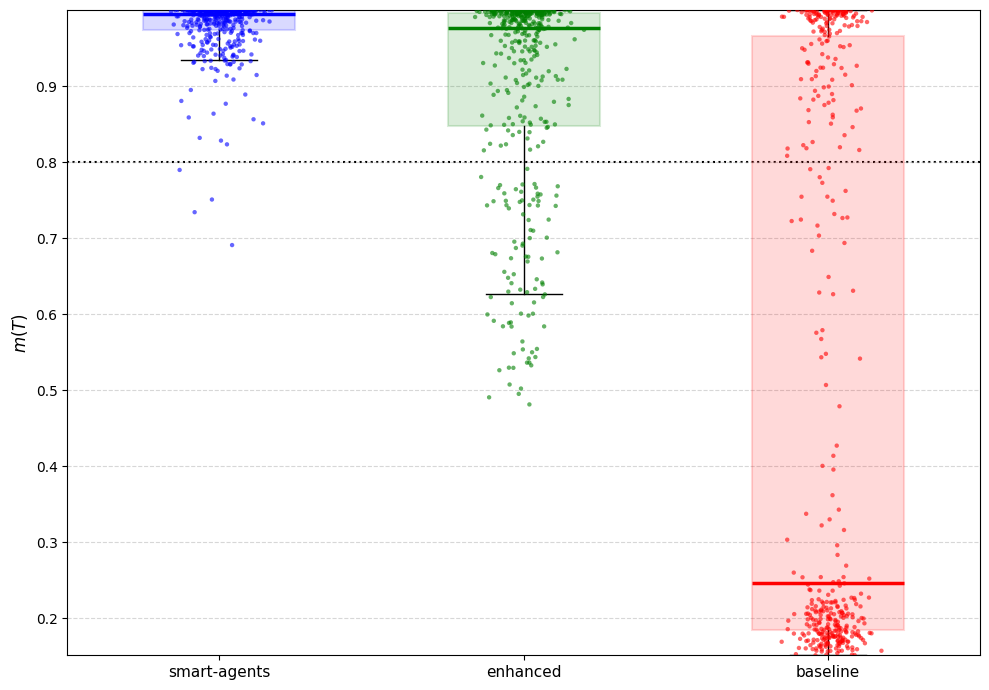

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# GLOBAL: aggregated boxplot for 'pop_last' across scenarios
pop_pod_rand['source'] = 'smart'
pop_pod_enh['source'] = 'enhanced'
pop_pod_base['source'] = 'baseline'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_enh, pop_pod_base], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 7))
sources_list = ['smart', 'enhanced', 'baseline']
colors = ['blue', 'green', 'red']
positions = range(len(sources_list))
data_for_boxplot = []
for source in sources_list:
    source_data = pop_pod_combined[pop_pod_combined['source'] == source]['pop_last'].values
    data_for_boxplot.append(source_data)
bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.15)
    patch.set_edgecolor(color)
    patch.set_linewidth(1.5)
for median, color in zip(bp['medians'], colors):
    median.set_color(color)
    median.set_linewidth(2.5)
for idx, source_data in enumerate(data_for_boxplot):
    jitter = np.random.normal(0, 0.06, size=len(source_data))
    x_positions = np.full(len(source_data), positions[idx]) + jitter
    ax.scatter(x_positions, source_data, color=colors[idx], alpha=0.6, edgecolors='none', s=10, zorder=3)
ax.set_ylabel(r'$m(T)$', fontsize=12)
# ax.set_title(r'Global Distribution of $m(T)$ by Scenario (Threshold = 0.8)', fontsize=14, fontweight='bold')
ax.set_ylim([pop_pod_combined['pop_last'].min(), pop_pod_combined['pop_last'].max()])
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=1)
ax.axhline(y=0.8, color='black', linestyle=':', linewidth=1.5, zorder=1)
ax.tick_params(axis='x', labelsize=11)
plt.tight_layout()
plt.show()

/tmp/ipykernel_23865/2717822533.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showfliers=False, zorder=2)
/tmp/ipykernel_23865/2717822533.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showfliers=False, zorder=2)
/tmp/ipykernel_23865/2717822533.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showflie

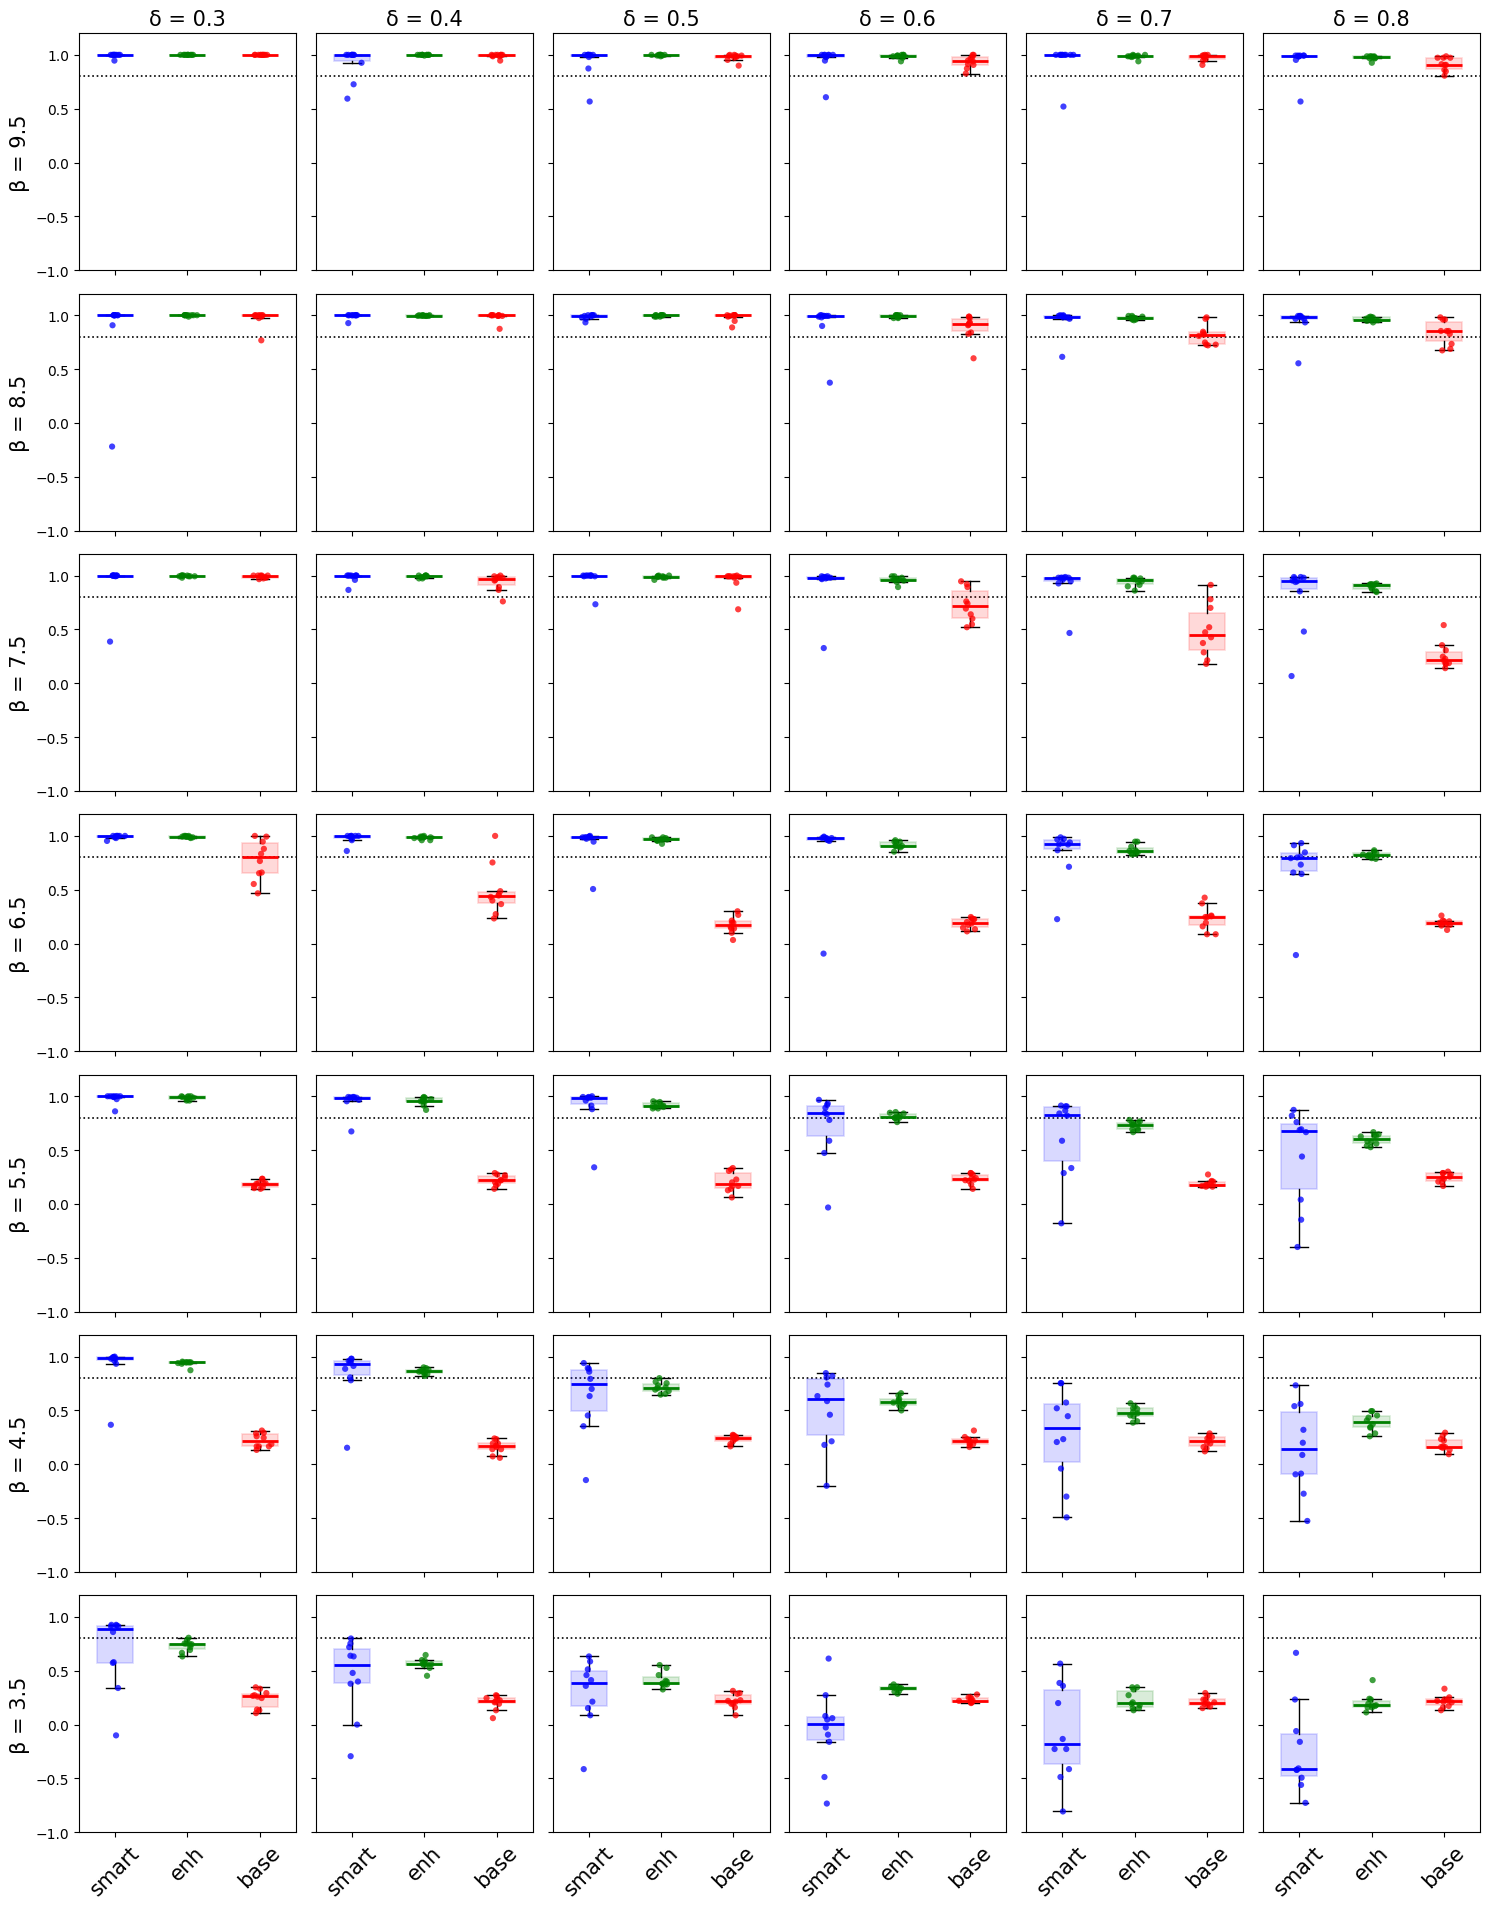

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# GRID: Boxplots of 'pod_last' for each (beta, delta) combination
pop_pod_rand['source'] = 'smart'
pop_pod_enh['source'] = 'enh'
pop_pod_base['source'] = 'base'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_enh, pop_pod_base], ignore_index=True)
betas = sorted(pop_pod_combined['beta'].unique(), reverse=True)
deltas = sorted(pop_pod_combined['delta'].unique())
fig, axes = plt.subplots(len(betas), len(deltas), figsize=(15, 15))
if len(betas) == 1:
    axes = axes.reshape(1, -1)
if len(deltas) == 1:
    axes = axes.reshape(-1, 1)
for i, beta in enumerate(betas):
    for j, delta in enumerate(deltas):
        ax = axes[i, j]
        mask = (pop_pod_combined['beta'] == beta) & (pop_pod_combined['delta'] == delta)
        subset = pop_pod_combined[mask]
        data_for_boxplot = []
        sources = []
        colors = ['blue', 'green', 'red']
        for source in ['smart', 'enh', 'base']:
            source_data = subset[subset['source'] == source]['pod_last']
            if len(source_data) > 0:
                data_for_boxplot.append(source_data.values)
                sources.append(source)
        if data_for_boxplot:
            positions = list(range(len(data_for_boxplot)))
            bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources, showfliers=False, zorder=2)
            for patch, color in zip(bp['boxes'], colors[:len(data_for_boxplot)]):
                patch.set_facecolor(color)
                patch.set_alpha(0.15)
                patch.set_edgecolor(color)
                patch.set_linewidth(1.2)
            for median, color in zip(bp['medians'], colors[:len(data_for_boxplot)]):
                median.set_color(color)
                median.set_linewidth(2)
            for idx, source_data in enumerate(data_for_boxplot):
                jitter = np.random.normal(0, 0.05, size=len(source_data))
                x_positions = np.full(len(source_data), positions[idx]) + jitter
                ax.scatter(x_positions, source_data, color=colors[idx], alpha=0.75, edgecolors='none', s=20, zorder=3)
        if i == 0:
            ax.set_title(f'δ = {delta}', fontsize=15)
        if j == 0:
            ax.set_ylabel(f'β = {beta}', fontsize=15)
        
        # Cambia il range dell'asse y a (-1, 0.2)
        ax.set_ylim([-1, 1.2])
        
        ax.tick_params(axis='x', rotation=45, labelsize=15)
        if j > 0:
            ax.set_ylabel('')
            
        # Toglie i numeri sull'asse verticale da delta = 0.4 in poi
        if delta >= 0.4:
            ax.tick_params(axis='y', labelleft=False)
            
        if i < len(betas) - 1:
            ax.set_xticklabels([])
            
for ax_row in axes.flatten():
    ax_row.axhline(y=0.8, color='black', linestyle=':', linewidth=1.2, zorder=1)
# plt.suptitle(r'Distribution of $M(T)$ by β and δ (Threshold = 0.8)', fontsize=14)
plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

/tmp/ipykernel_23865/517154050.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)


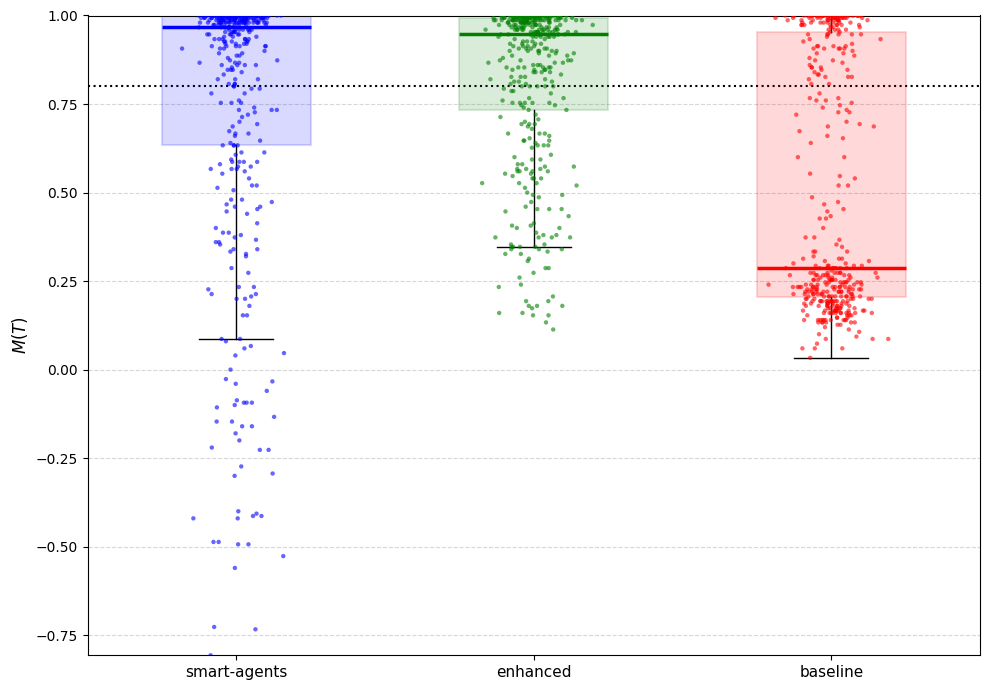

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# GLOBAL: aggregated boxplot for 'pop_last' across scenarios
pop_pod_rand['source'] = 'smart-agents'
pop_pod_enh['source'] = 'enhanced'
pop_pod_base['source'] = 'baseline'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_enh, pop_pod_base], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 7))
sources_list = ['smart-agents', 'enhanced', 'baseline']
colors = ['blue', 'green', 'red']
positions = range(len(sources_list))
data_for_boxplot = []
for source in sources_list:
    source_data = pop_pod_combined[pop_pod_combined['source'] == source]['pod_last'].values
    data_for_boxplot.append(source_data)
bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.15)
    patch.set_edgecolor(color)
    patch.set_linewidth(1.5)
for median, color in zip(bp['medians'], colors):
    median.set_color(color)
    median.set_linewidth(2.5)
for idx, source_data in enumerate(data_for_boxplot):
    jitter = np.random.normal(0, 0.06, size=len(source_data))
    x_positions = np.full(len(source_data), positions[idx]) + jitter
    ax.scatter(x_positions, source_data, color=colors[idx], alpha=0.6, edgecolors='none', s=10, zorder=3)
ax.set_ylabel(r'$M(T)$', fontsize=12)
# ax.set_title(r'Global Distribution of $M by Scenario (Threshold = 0.8)', fontsize=14, fontweight='bold')
ax.set_ylim([pop_pod_combined['pod_last'].min(), pop_pod_combined['pod_last'].max()])
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=1)
ax.axhline(y=0.8, color='black', linestyle=':', linewidth=1.5, zorder=1)
ax.tick_params(axis='x', labelsize=11)
plt.tight_layout()
plt.show()